# Sampler interface

This notebook provides the interface with `Cobaya` to run an MCMC parameter inference on the mock datasets generated with `horizon`.

## Import packages

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from chainconsumer import Chain, ChainConsumer, PlotConfig

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif"
})

In [5]:
green        = ['#a6dba0','#5aae61','#1b7837']
purple       = ['#c2a5cf', '#9970ab', '#762a83']
analogous    = ['#a0c3db', '#dbb7a0']
warm         = ['#fdcc8a', '#fc8d59', '#d7301f']
cool         = ['#41b6c4', '#2c7fb8', '#253494']

### Run Cobaya

In [6]:
from cobaya.run import run
from likelihood import DDRlike

info = {'params': {
                  'A': {'prior': {'min': -1., 'max': 1.},
                            'ref': {'dist': 'norm', 'loc': 1, 'scale': 0.1},
                            'proposal': 0.05,
                            'latex': 'A'},
                   'H0': {'prior': {'min': 60., 'max': 80.},
                            'ref': {'dist': 'norm', 'loc': 67, 'scale': 0.1},
                            'proposal': 0.1,
                            'latex': r'H_0'},
                   'Omegam': {'prior': {'min': 0.2, 'max': 0.4},
                            'ref': {'dist': 'norm', 'loc': 0.314, 'scale': 0.05},
                            'proposal': 0.01,
                            'latex': r'\Omega_{\rm m}'}
                            },
        'sampler': {'mcmc': {'max_tries': 10000}},  # Increase for production runs
        'output': 'chains/test',
        'likelihood': {'DDRlike': DDRlike},
        'force': True
        }


info['debug'] = False

# Run MCMC sampling
updated_info, sampler = run(info)

[output] Output to be read-from/written-into folder 'chains', with prefix 'test'
[output] Found existing info files with the requested output prefix: 'chains/test'
[output] Will delete previous products ('force' was requested).
[mcmc] Getting initial point... (this may take a few seconds)
[mcmc] Initial point: A:0.9700165, H0:67.17334, Omegam:0.2853812
[model] Measuring speeds... (this may take a few seconds)
[model] Setting measured speeds (per sec): {DDRlike: 79.1}
[mcmc] Covariance matrix not present. We will start learning the covariance of the proposal earlier: R-1 = 30 (would be 2 if all params loaded).
[mcmc] Sampling!
[mcmc] Progress @ 2026-02-03 12:22:24 : 1 steps taken, and 0 accepted.


/home/nataliehogg/Documents/Projects/davide/horizon/tools/theory.py:72: RuntimeWarning: invalid value encountered in sqrt
  self.eta = np.sqrt(1 / P)


[mcmc] Learn + convergence test @ 120 samples accepted.
[mcmc]  - Acceptance rate: 0.329
[mcmc]  - Convergence of means: R-1 = 7.426737 after 96 accepted steps
[mcmc]  - Updated covariance matrix of proposal pdf.


/home/nataliehogg/Documents/Projects/davide/horizon/tools/theory.py:72: RuntimeWarning: invalid value encountered in sqrt
  self.eta = np.sqrt(1 / P)


[mcmc] Learn + convergence test @ 240 samples accepted.
[mcmc]  - Acceptance rate: 0.315
[mcmc]  - Convergence of means: R-1 = 9.040701 after 192 accepted steps
[mcmc]  - Updated covariance matrix of proposal pdf.


/home/nataliehogg/Documents/Projects/davide/horizon/tools/theory.py:72: RuntimeWarning: invalid value encountered in sqrt
  self.eta = np.sqrt(1 / P)


... (99 outputs left out)

/home/nataliehogg/Documents/Projects/davide/horizon/tools/theory.py:72: RuntimeWarning: invalid value encountered in sqrt
  self.eta = np.sqrt(1 / P)


[mcmc] Learn + convergence test @ 5400 samples accepted.
[mcmc]  - Acceptance rate: 0.158
[mcmc]  - Convergence of means: R-1 = 0.009675 after 4320 accepted steps
[mcmc]  - Updated covariance matrix of proposal pdf.


/home/nataliehogg/Documents/Projects/davide/horizon/tools/theory.py:72: RuntimeWarning: invalid value encountered in sqrt
  self.eta = np.sqrt(1 / P)


[mcmc] Learn + convergence test @ 5520 samples accepted.
[mcmc]  - Acceptance rate: 0.157
[mcmc]  - Convergence of means: R-1 = 0.007214 after 4416 accepted steps
[mcmc]  - Convergence of bounds: R-1 = 0.087766 after 5520 accepted steps
[mcmc] The run has converged!
[mcmc] Sampling complete after 5520 accepted steps.


### Plot contours with chainconsumer

Available columns: ['weight', 'minuslogpost', 'A', 'H0', 'Omegam', 'minuslogprior', 'minuslogprior__0', 'chi2', 'chi2__DDRlike']
Chain shape: (5520, 9)



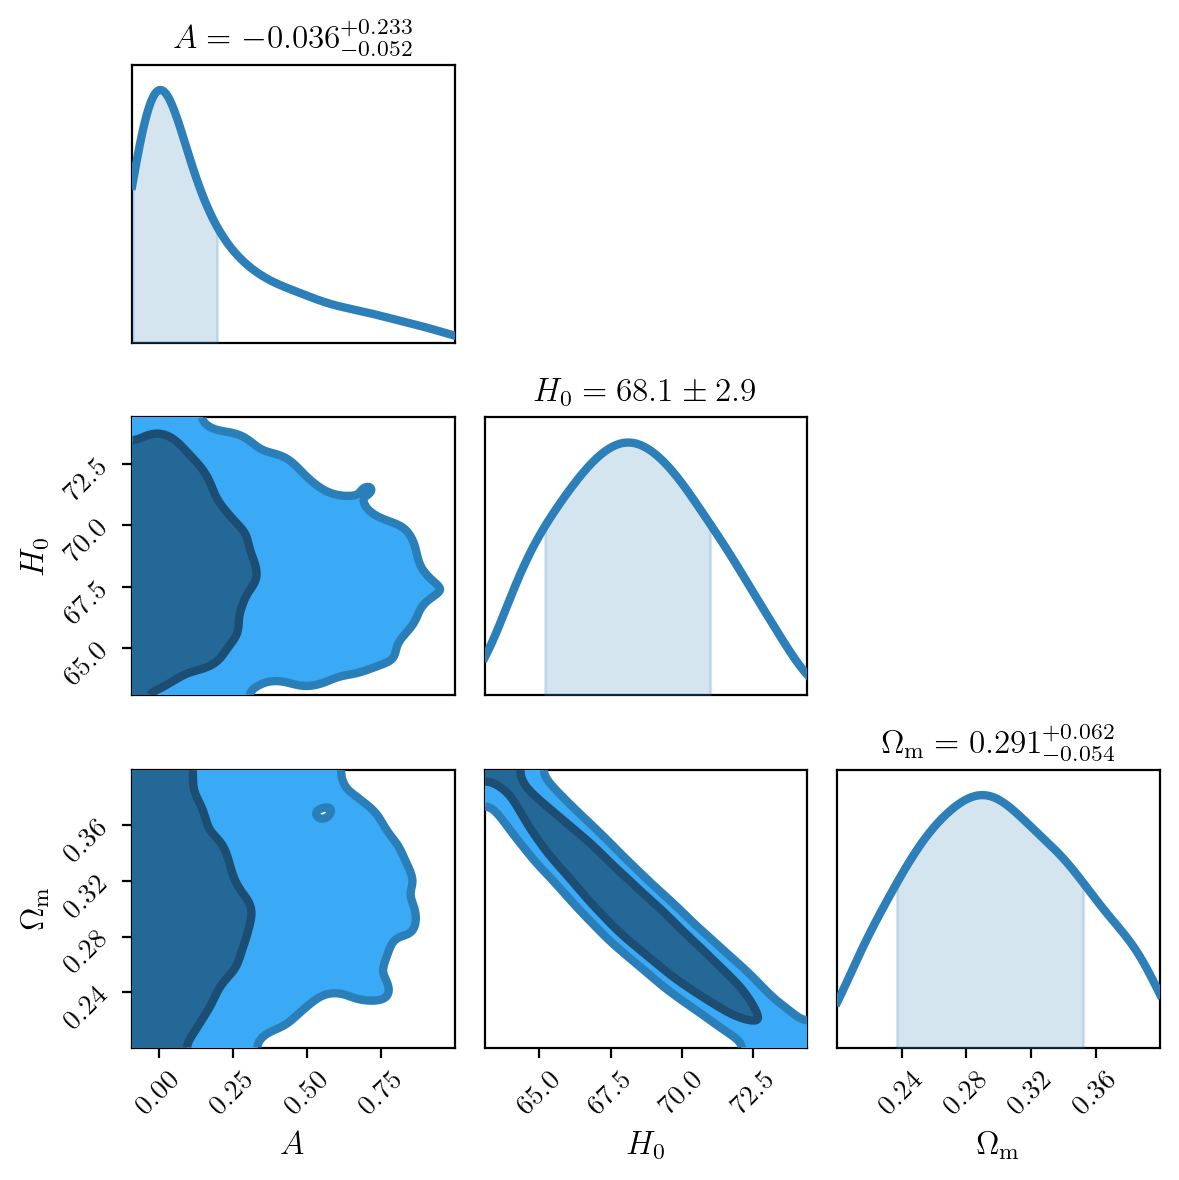

In [8]:
# Read the chain file from Cobaya output
chain_file = 'chains/test.1.txt'

# Read the header line to get column names
with open(chain_file, 'r') as f:
    header_line = f.readline()

# Extract column names from the header (remove # and split)
column_names = header_line.strip('#').split()

# Read the chain data with explicit column names
df = pd.read_csv(chain_file, sep=r'\s+', comment='#', names=column_names, header=None)

# Print available columns for debugging
print("Available columns:", df.columns.tolist())
print(f"Chain shape: {df.shape}")
print()

# Extract parameters for the triangle plot
params = ['A', 'H0', 'Omegam']
weights = df['weight'].values

# Create ChainConsumer object
c = ChainConsumer()

# Add the chain with proper column names and weights
c.add_chain(Chain(samples=df[params], weights=weights, name="DDR", 
                  bins=10, smooth=20,
                  shade_gradient=0.8, linewidth=3, color=cool[1]))

c.set_plot_config(PlotConfig(labels={'A': r'$A$', 'H0': r'$H_0$', 'Omegam': r'$\Omega_{\rm m}$'}, 
                            usetex=True,serif=True))

# Generate triangle plot
fig = c.plotter.plot(figsize=(6,6))

# Adjust layout for better display
plt.tight_layout()
plt.show()